# ⏰ "○○을 비춰라" 기상 미션 알람 — YOLO11n 10종 파인튜닝

알람을 끄려면 **제시된 물건을 카메라에 비춰야** 한다. 아무 컵이나 되는 *일반 모델*이 필요하다.

| 단계 | 내용 |
|---|---|
| 1 | 클래스 10종 정하기 (COCO가 아는 4종 + 새로 6종) |
| 2 | Open Images V7에서 데이터 받기 → YOLO 형식 |
| 3 | 데이터 살펴보기 (개수, 예시, **빠진 라벨** 함정) |
| 4 | 모델 구조 (백본 · 넥 · 헤드, 무엇이 새로 초기화되나) |
| 5 | 기준선: COCO YOLO 그대로 기존 4종 |
| 6 | 실험 A 전체 미세조정 / 실험 B 백본 고정 |
| 7 | 평가: 클래스별 지표, 혼동행렬, 기준선 비교 |
| 8 | ONNX 내보내기 + 웹앱과 같은 계산으로 검증 |
| 9 | 직접 찍은 사진으로 미션 통과율 |

## 0. 설정

In [1]:
import sys, time, shutil, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
from IPython.display import Image, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config as C, data as D, evaluate as E

QUICK = False                      # True: 클래스당 20장 · 2에폭 (끝까지 도는지만 확인)
PER_CLASS = {'train': 20 if QUICK else 400, 'validation': 10 if QUICK else 80}
EPOCHS = 2 if QUICK else 50
DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
DATA = ROOT / 'data'
YOLO_DIR = DATA / ('yolo_quick' if QUICK else 'yolo')
RUNS = ROOT / 'runs'
plt.rcParams['font.family'] = 'AppleGothic'; plt.rcParams['axes.unicode_minus'] = False
print('device:', DEVICE, '| QUICK:', QUICK)

/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps | QUICK: False


## 1. 클래스 10종

Open Images는 라벨이 **계층 구조**다 (모자 ⊃ 페도라·솜브레로…). 하위 라벨을 상위 클래스로 합친다.

In [2]:
pd.DataFrame([dict(id=c.id, 미션=C.mission_text(c), 키=c.key,
                   OpenImages라벨=', '.join(c.oi_labels),
                   COCO번호=c.coco_id if c.coco_id is not None else '-') for c in C.CLASSES])

,id,미션,키,OpenImages라벨,COCO번호
0,0,🖱️ 마우스를 비춰라,mouse,Computer mouse,64
1,1,☂️ 우산을 비춰라,umbrella,Umbrella,25
2,2,📖 책을 비춰라,book,Book,73
3,3,🪥 칫솔을 비춰라,toothbrush,Toothbrush,79
4,4,🧢 모자를 비춰라,hat,"Hat, Fedora, Sun hat, Cowboy hat, Sombrero",-
5,5,🚪 문을 비춰라,door,Door,-
6,6,🧻 휴지를 비춰라,toilet_paper,Toilet paper,-
7,7,🧦 양말을 비춰라,sock,Sock,-
8,8,👟 신발을 비춰라,shoe,"Footwear, Boot, High heels, Sandal",-
9,9,👓 안경을 비춰라,glasses,"Glasses, Sunglasses",-


## 2. 데이터 받기 (Open Images V7 → YOLO 형식)

클래스마다 따로 받아 합친다. 처음엔 주석 파일을 받느라 오래 걸린다. 한 번 받으면 캐시를 쓴다.

Open Images는 같은 물건을 상위·하위 라벨(예: Footwear와 Boot)로 두 번 그리기도 해서, 합친 뒤 같은 클래스끼리 IoU 0.7 이상 겹치는 박스는 하나만 남긴다.

In [3]:
views = {}
for split, yolo_split in [('train', 'train'), ('validation', 'val')]:
    ds = D.load_split(split, PER_CLASS[split])
    views[yolo_split] = D.to_mission_view(ds)
    if not (YOLO_DIR / 'labels' / yolo_split).exists():
        D.export_yolo(views[yolo_split], YOLO_DIR, yolo_split)
        print(yolo_split, '겹친 박스 제거:', D.dedupe_labels(YOLO_DIR, yolo_split))
YAML = YOLO_DIR / 'dataset.yaml'
print(YAML.read_text())

Necessary images already downloaded


Existing download of split 'train' is sufficient


Loading existing dataset 'oi-train-mouse-400'. To reload from disk, either delete the existing dataset or provide a custom `dataset_name` to use


Converting existing index 'filepath' to unique on dataset 'wakeup-train-400'


Necessary images already downloaded


Existing download of split 'train' is sufficient


... (748 outputs left out)

  77% |█████████████/---| 334/432 [542.6ms elapsed, 159.2ms remaining, 615.5 samples/s] 

  97% |████████████████-| 418/432 [642.7ms elapsed, 21.5ms remaining, 650.4 samples/s]  

 100% |█████████████████| 432/432 [658.0ms elapsed, 0s remaining, 656.6 samples/s]      


val 겹친 박스 제거: 348
names:
  0: mouse
  1: umbrella
  2: book
  3: toothbrush
  4: hat
  5: door
  6: toilet_paper
  7: sock
  8: shoe
  9: glasses
path: "/Users/kks/Downloads/2026.07-12_\uC5EC\uB984\uBC29\uD559\xB72\uD559\uAE30/ROKEY_\uBD80\
  \uD2B8\uCEA0\uD504/\u1103\u1175\u11B8\u1105\u1165\u1102\u1175\u11BC/wakeup_mission/data/yolo"
train: ./images/train/
val: ./images/val/



## 3. 데이터 살펴보기

In [4]:
tables = {s: D.count_table(v).set_index('id') for s, v in views.items()}
summary = tables['train'][['클래스', '구분']].copy()
summary['train 사진'] = tables['train']['사진']; summary['train 박스'] = tables['train']['박스']
summary['val 사진'] = tables['val']['사진'];     summary['val 박스'] = tables['val']['박스']
summary

,클래스,구분,train 사진,train 박스,val 사진,val 박스
id,,,,,,
0,마우스,기존(COCO),400,474,19,24
1,우산,기존(COCO),404,1033,27,40
2,책,기존(COCO),405,2187,80,672
3,칫솔,기존(COCO),113,219,10,16
4,모자,새로,427,1000,91,215
5,문,새로,400,633,80,111
6,휴지,새로,226,377,4,5
7,양말,새로,400,1128,10,25
8,신발,새로,421,2628,82,404


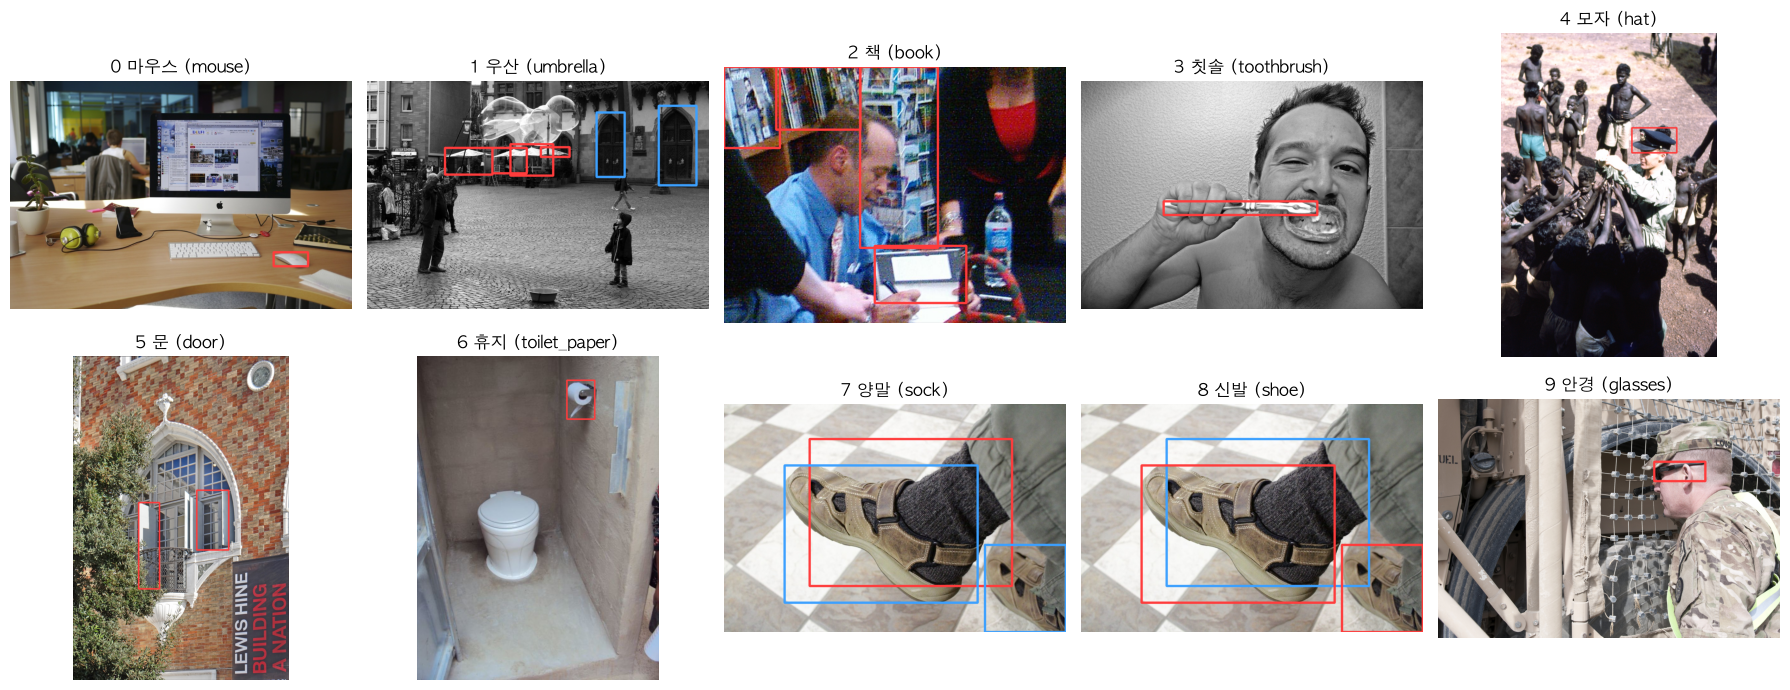

In [5]:
# 클래스별 예시 한 장씩 (박스 그려서)
import cv2
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, c in zip(axes.flat, C.CLASSES):
    lab = next(p for p in sorted((YOLO_DIR / 'labels' / 'train').glob('*.txt'))
               if any(r.split()[0] == str(c.id) for r in p.read_text().splitlines()))
    img_path = next((YOLO_DIR / 'images' / 'train').glob(lab.stem + '.*'))
    img = cv2.imread(str(img_path))[:, :, ::-1].copy()
    h, w = img.shape[:2]
    for r in lab.read_text().splitlines():
        k, cx, cy, bw, bh = r.split(); cx, cy, bw, bh = map(float, (cx, cy, bw, bh))
        color = (255, 60, 60) if int(k) == c.id else (60, 160, 255)
        cv2.rectangle(img, (int((cx - bw/2)*w), int((cy - bh/2)*h)), (int((cx + bw/2)*w), int((cy + bh/2)*h)), color, max(2, w // 200))
    ax.imshow(img); ax.set_title(f'{c.id} {c.ko} ({c.key})'); ax.axis('off')   # 이모지는 matplotlib 글꼴에 없음
plt.tight_layout(); plt.show()

### ⚠️ 빠진 라벨 함정

Open Images는 사진마다 **확인한 클래스만** 박스를 그린다. 아래는 "신발" 라벨이 있는 사진 중 **양말 라벨은 없는** 사진이다.
양말이 보이는데 라벨이 없다면, 모델은 그 양말을 **배경**으로 배운다 → 양말 Recall이 낮아질 수 있다.

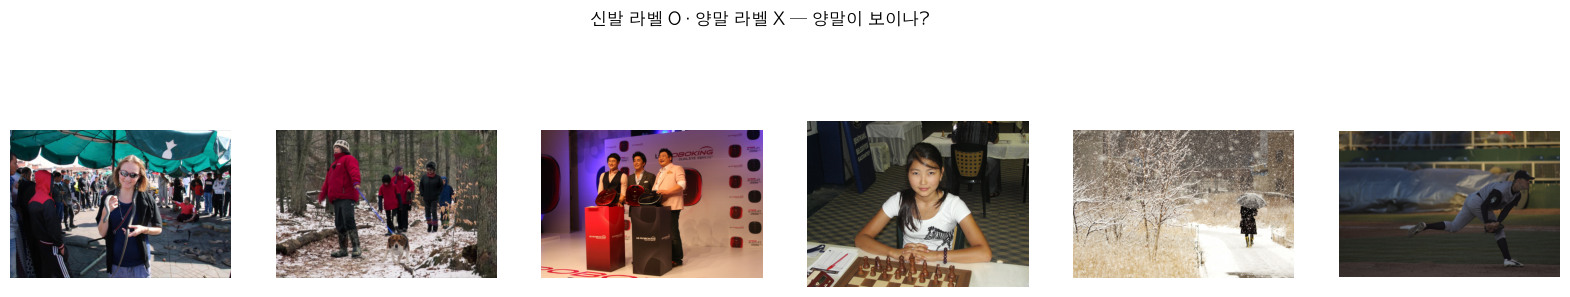

In [6]:
from fiftyone import ViewField as F
v = views['train']
has = lambda k: F('ground_truth.detections').filter(F('label') == k).length() > 0
shoe_no_sock = v.match(has('shoe') & ~has('sock')).take(6, seed=0)
fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for ax, s in zip(axes, shoe_no_sock):
    ax.imshow(plt.imread(s.filepath)); ax.axis('off')
plt.suptitle('신발 라벨 O · 양말 라벨 X — 양말이 보이나?'); plt.show()

## 4. 모델 구조 — YOLO11n

```
입력 640×640×3
 ▼ 백본: Conv → Conv → C3k2 → … → SPPF → C2PSA     ─ P3(80×80) · P4(40×40) · P5(20×20)
 ▼ 넥 (PAN-FPN): 위→아래, 아래→위로 크기가 다른 특징 섞기
 ▼ 헤드 (Detect, 크기 3개마다)
     ├ 박스 갈래:   4×16 채널 (DFL)
     └ 클래스 갈래: nc 채널  ← 80 → 10 으로 바뀌어 **이 층만 새로 초기화**
 ▼ 8,400개 위치 × [박스 4 + 클래스 10] → 신뢰도 거르기 → NMS
```

- **C3k2**: 입력을 나눠 일부만 합성곱 → 다시 합침 (잔차 연결과 비슷)
- **SPPF**: 맥스풀링을 겹쳐 넓은 범위를 봄 · **C2PSA**: 어텐션
- 클래스 점수는 softmax가 아니라 **클래스별 시그모이드(BCE)** → "신발 0.7, 양말 0.6"이 동시에 가능

In [7]:
base = YOLO('yolo11n.pt')
base.info(detailed=False)
head = base.model.model[-1]
print('헤드 클래스 갈래 마지막 층:', [m[-1] for m in head.cv3])   # out_channels=80 → 파인튜닝하면 10

YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs


헤드 클래스 갈래 마지막 층: [Conv2d(80, 80, kernel_size=(1, 1), stride=(1, 1)), Conv2d(80, 80, kernel_size=(1, 1), stride=(1, 1)), Conv2d(80, 80, kernel_size=(1, 1), stride=(1, 1))]


## 5. 기준선 — COCO YOLO 그대로 (기존 4종만)

기존 4종이 있는 val 사진만 모아, **같은 사진**으로 기준선과 파인튜닝 모델을 비교한다.

In [8]:
OLD_DIR = DATA / ('val_old_quick' if QUICK else 'val_old')
if not (OLD_DIR / 'coco.yaml').exists():
    D.make_old_subset(YOLO_DIR, OLD_DIR)
coco_ids = [c.coco_id for c in C.OLD]
m0 = base.val(data=str(OLD_DIR / 'coco.yaml'), classes=coco_ids, imgsz=640, device=DEVICE,
              project=str(RUNS), name='baseline_val', exist_ok=True, plots=False, verbose=False)
baseline = E.per_class_table(m0, base.names)
baseline

Ultralytics 8.4.208 🚀 Python-3.12.15 torch-2.15.0 MPS (Apple M4 Pro)


YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3743.1±2667.9 MB/s, size: 278.0 KB)


val: Scanning /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/val_old/coco/labels/val... 136 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 136/136 3.8Kit/s 0.0s

val: New cache created: /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/val_old/coco/labels/val.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 4.4it/s 2.1s

                   all        136        675      0.414      0.626      0.507      0.406


Speed: 0.1ms preprocess, 5.5ms inference, 0.0ms loss, 3.2ms postprocess per image


,id,클래스,P,R,mAP50,mAP50-95
0,25,umbrella,0.463,0.771,0.652,0.479
1,64,mouse,0.845,0.906,0.853,0.698
2,73,book,0.126,0.076,0.036,0.021
3,79,toothbrush,0.222,0.750,0.487,0.427


## 6. 학습 — 실험 A (전체 미세조정) vs 실험 B (백본 고정)

- **A**: 모든 층을 작은 학습률로 학습
- **B**: `freeze=10` → 백본(앞 10개 층)은 COCO 가중치 그대로, 넥·헤드만 학습

> "새 6종만 학습해서 기존 4종을 잊는지 보기"는 하지 않는다. 클래스 수가 바뀌면 클래스 층이 새로 초기화되므로,
> 그건 **잊은 게 아니라 배운 적이 없는 것**이다. 대신 기준선과 비교해 기존 4종이 나빠졌는지 본다.

Early Stopping: `patience=10` — 검증 fitness(mAP 기반 점수, 버전마다 식이 조금 다름)가 10에폭 동안 안 오르면 멈추고 `best.pt`를 남긴다.

In [9]:
EXPS = {'A_full': dict(freeze=None), 'B_freeze10': dict(freeze=10)}
train_time = {}
for name, extra in EXPS.items():
    if (RUNS / name / 'weights' / 'best.pt').exists() and not QUICK:
        print(name, '이미 학습됨 → 건너뜀'); continue
    t0 = time.time()
    YOLO('yolo11n.pt').train(data=str(YAML), epochs=EPOCHS, imgsz=640, batch=16, patience=10,
                             device=DEVICE, project=str(RUNS), name=name, exist_ok=True,
                             seed=0, workers=4, plots=True, **extra)
    train_time[name] = time.time() - t0
train_time

Ultralytics 8.4.208 🚀 Python-3.12.15 torch-2.15.0 MPS (Apple M4 Pro)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/yolo/dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=A_full, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, ov

Overriding model.yaml nc=80 with nc=10



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (686 outputs left out)

               glasses         83        123      0.897      0.495      0.728      0.483


Speed: 0.1ms preprocess, 4.5ms inference, 0.0ms loss, 2.2ms postprocess per image


Results saved to /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/B_freeze10


{'A_full': 6927.5847289562225, 'B_freeze10': 4652.665542840958}

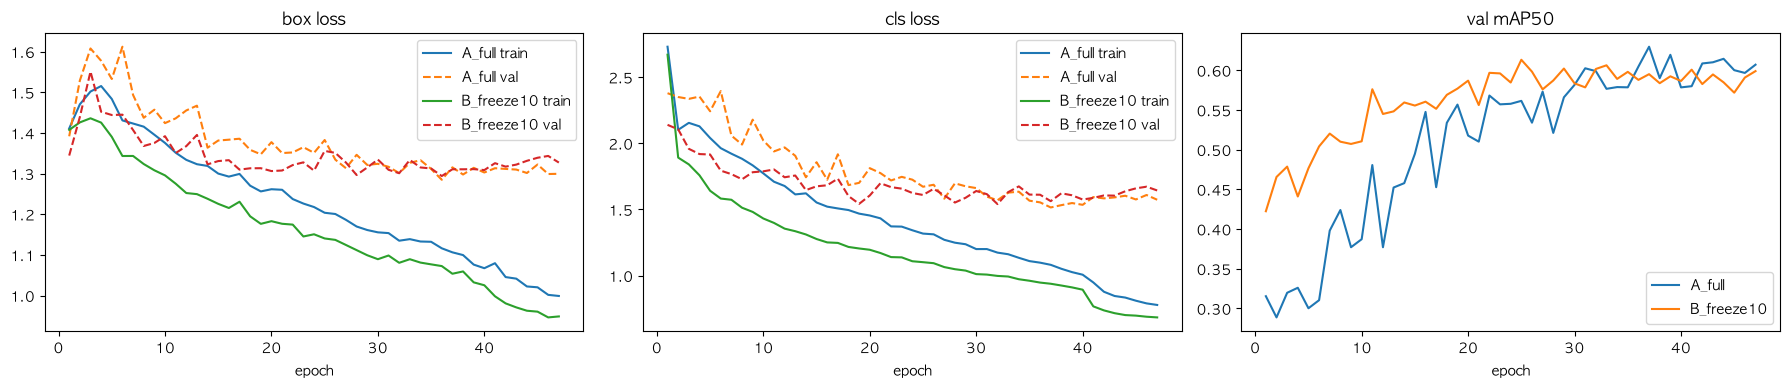

In [10]:
# 학습곡선 (ultralytics가 저장한 results.csv)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for name in EXPS:
    r = pd.read_csv(RUNS / name / 'results.csv'); r.columns = r.columns.str.strip()
    axes[0].plot(r['epoch'], r['train/box_loss'], label=f'{name} train'); axes[0].plot(r['epoch'], r['val/box_loss'], '--', label=f'{name} val')
    axes[1].plot(r['epoch'], r['train/cls_loss'], label=f'{name} train'); axes[1].plot(r['epoch'], r['val/cls_loss'], '--', label=f'{name} val')
    axes[2].plot(r['epoch'], r['metrics/mAP50(B)'], label=name)
for ax, t in zip(axes, ['box loss', 'cls loss', 'val mAP50']): ax.set_title(t); ax.legend(); ax.set_xlabel('epoch')
plt.tight_layout(); plt.show()

## 7. 평가

In [11]:
results, models = {}, {}
for name in EXPS:
    models[name] = YOLO(RUNS / name / 'weights' / 'best.pt')
    m = models[name].val(data=str(YAML), imgsz=640, device=DEVICE, project=str(RUNS),
                         name=f'{name}_val', exist_ok=True, plots=True, verbose=False)
    results[name] = E.per_class_table(m, C.KEYS).set_index('id')
    results[name].loc['전체', ['mAP50', 'R']] = [m.box.map50, m.box.mr]
compare = pd.DataFrame({
    '클래스': [c.ko for c in C.CLASSES] + ['전체'],
    '구분': ['기존' if c.coco_id is not None else '새로' for c in C.CLASSES] + [''],
    **{f'{n} mAP50': list(results[n]['mAP50'].reindex(list(range(10)) + ['전체'])) for n in EXPS},
    **{f'{n} R': list(results[n]['R'].reindex(list(range(10)) + ['전체'])) for n in EXPS},
})
compare

Ultralytics 8.4.208 🚀 Python-3.12.15 torch-2.15.0 MPS (Apple M4 Pro)


YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4201.4±991.2 MB/s, size: 410.2 KB)


val: Scanning /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/yolo/labels/val.cache... 432 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 432/432 201.3Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 3.8it/s 7.2s

                   all        432       1393       0.73       0.59      0.634      0.468


... (7 outputs left out)

                   all        432       1393      0.623      0.545      0.589      0.436


Speed: 0.1ms preprocess, 1.5ms inference, 0.0ms loss, 2.6ms postprocess per image


Results saved to /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/B_freeze10_val


,클래스,구분,A_full mAP50,B_freeze10 mAP50,A_full R,B_freeze10 R
0,마우스,기존,0.870000,0.921000,0.87500,0.89000
1,우산,기존,0.698000,0.636000,0.62900,0.68600
2,책,기존,0.334000,0.309000,0.30800,0.28300
3,칫솔,기존,0.853000,0.775000,0.81100,0.75000
4,모자,새로,0.714000,0.712000,0.54200,0.63400
5,문,새로,0.363000,0.327000,0.21900,0.20000
6,휴지,새로,0.824000,0.685000,0.80000,0.60000
7,양말,새로,0.505000,0.373000,0.88200,0.61800
8,신발,새로,0.424000,0.418000,0.26000,0.27900
9,안경,새로,0.753000,0.730000,0.57700,0.51100


In [12]:
# 기존 4종: 기준선 vs A vs B (같은 사진)
old_rows = {'기준선(COCO)': list(baseline.set_index('id')['mAP50'].reindex([c.coco_id for c in C.OLD]))}   # COCO 번호 순서 → 우리 순서
for name in EXPS:
    m = models[name].val(data=str(OLD_DIR / 'ours.yaml'), classes=[c.id for c in C.OLD], imgsz=640,
                         device=DEVICE, project=str(RUNS), name=f'{name}_old', exist_ok=True, plots=False, verbose=False)
    old_rows[name] = list(E.per_class_table(m, C.KEYS).set_index('id')['mAP50'].reindex([c.id for c in C.OLD]))
pd.DataFrame(old_rows, index=[c.ko for c in C.OLD])

Ultralytics 8.4.208 🚀 Python-3.12.15 torch-2.15.0 MPS (Apple M4 Pro)


YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3483.0±1697.4 MB/s, size: 325.9 KB)


val: Scanning /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/val_old/ours/labels/val... 136 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 136/136 3.9Kit/s 0.0s

val: New cache created: /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/val_old/ours/labels/val.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 5.4it/s 1.7s

... (6 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 6.1it/s 1.5s

                   all        136        675      0.659      0.656      0.668      0.519


Speed: 0.2ms preprocess, 1.6ms inference, 0.0ms loss, 2.7ms postprocess per image


,기준선(COCO),A_full,B_freeze10
마우스,0.853,0.898,0.948
우산,0.652,0.722,0.608
책,0.036,0.334,0.314
칫솔,0.487,0.837,0.801


앱에 쓸 모델: A_full


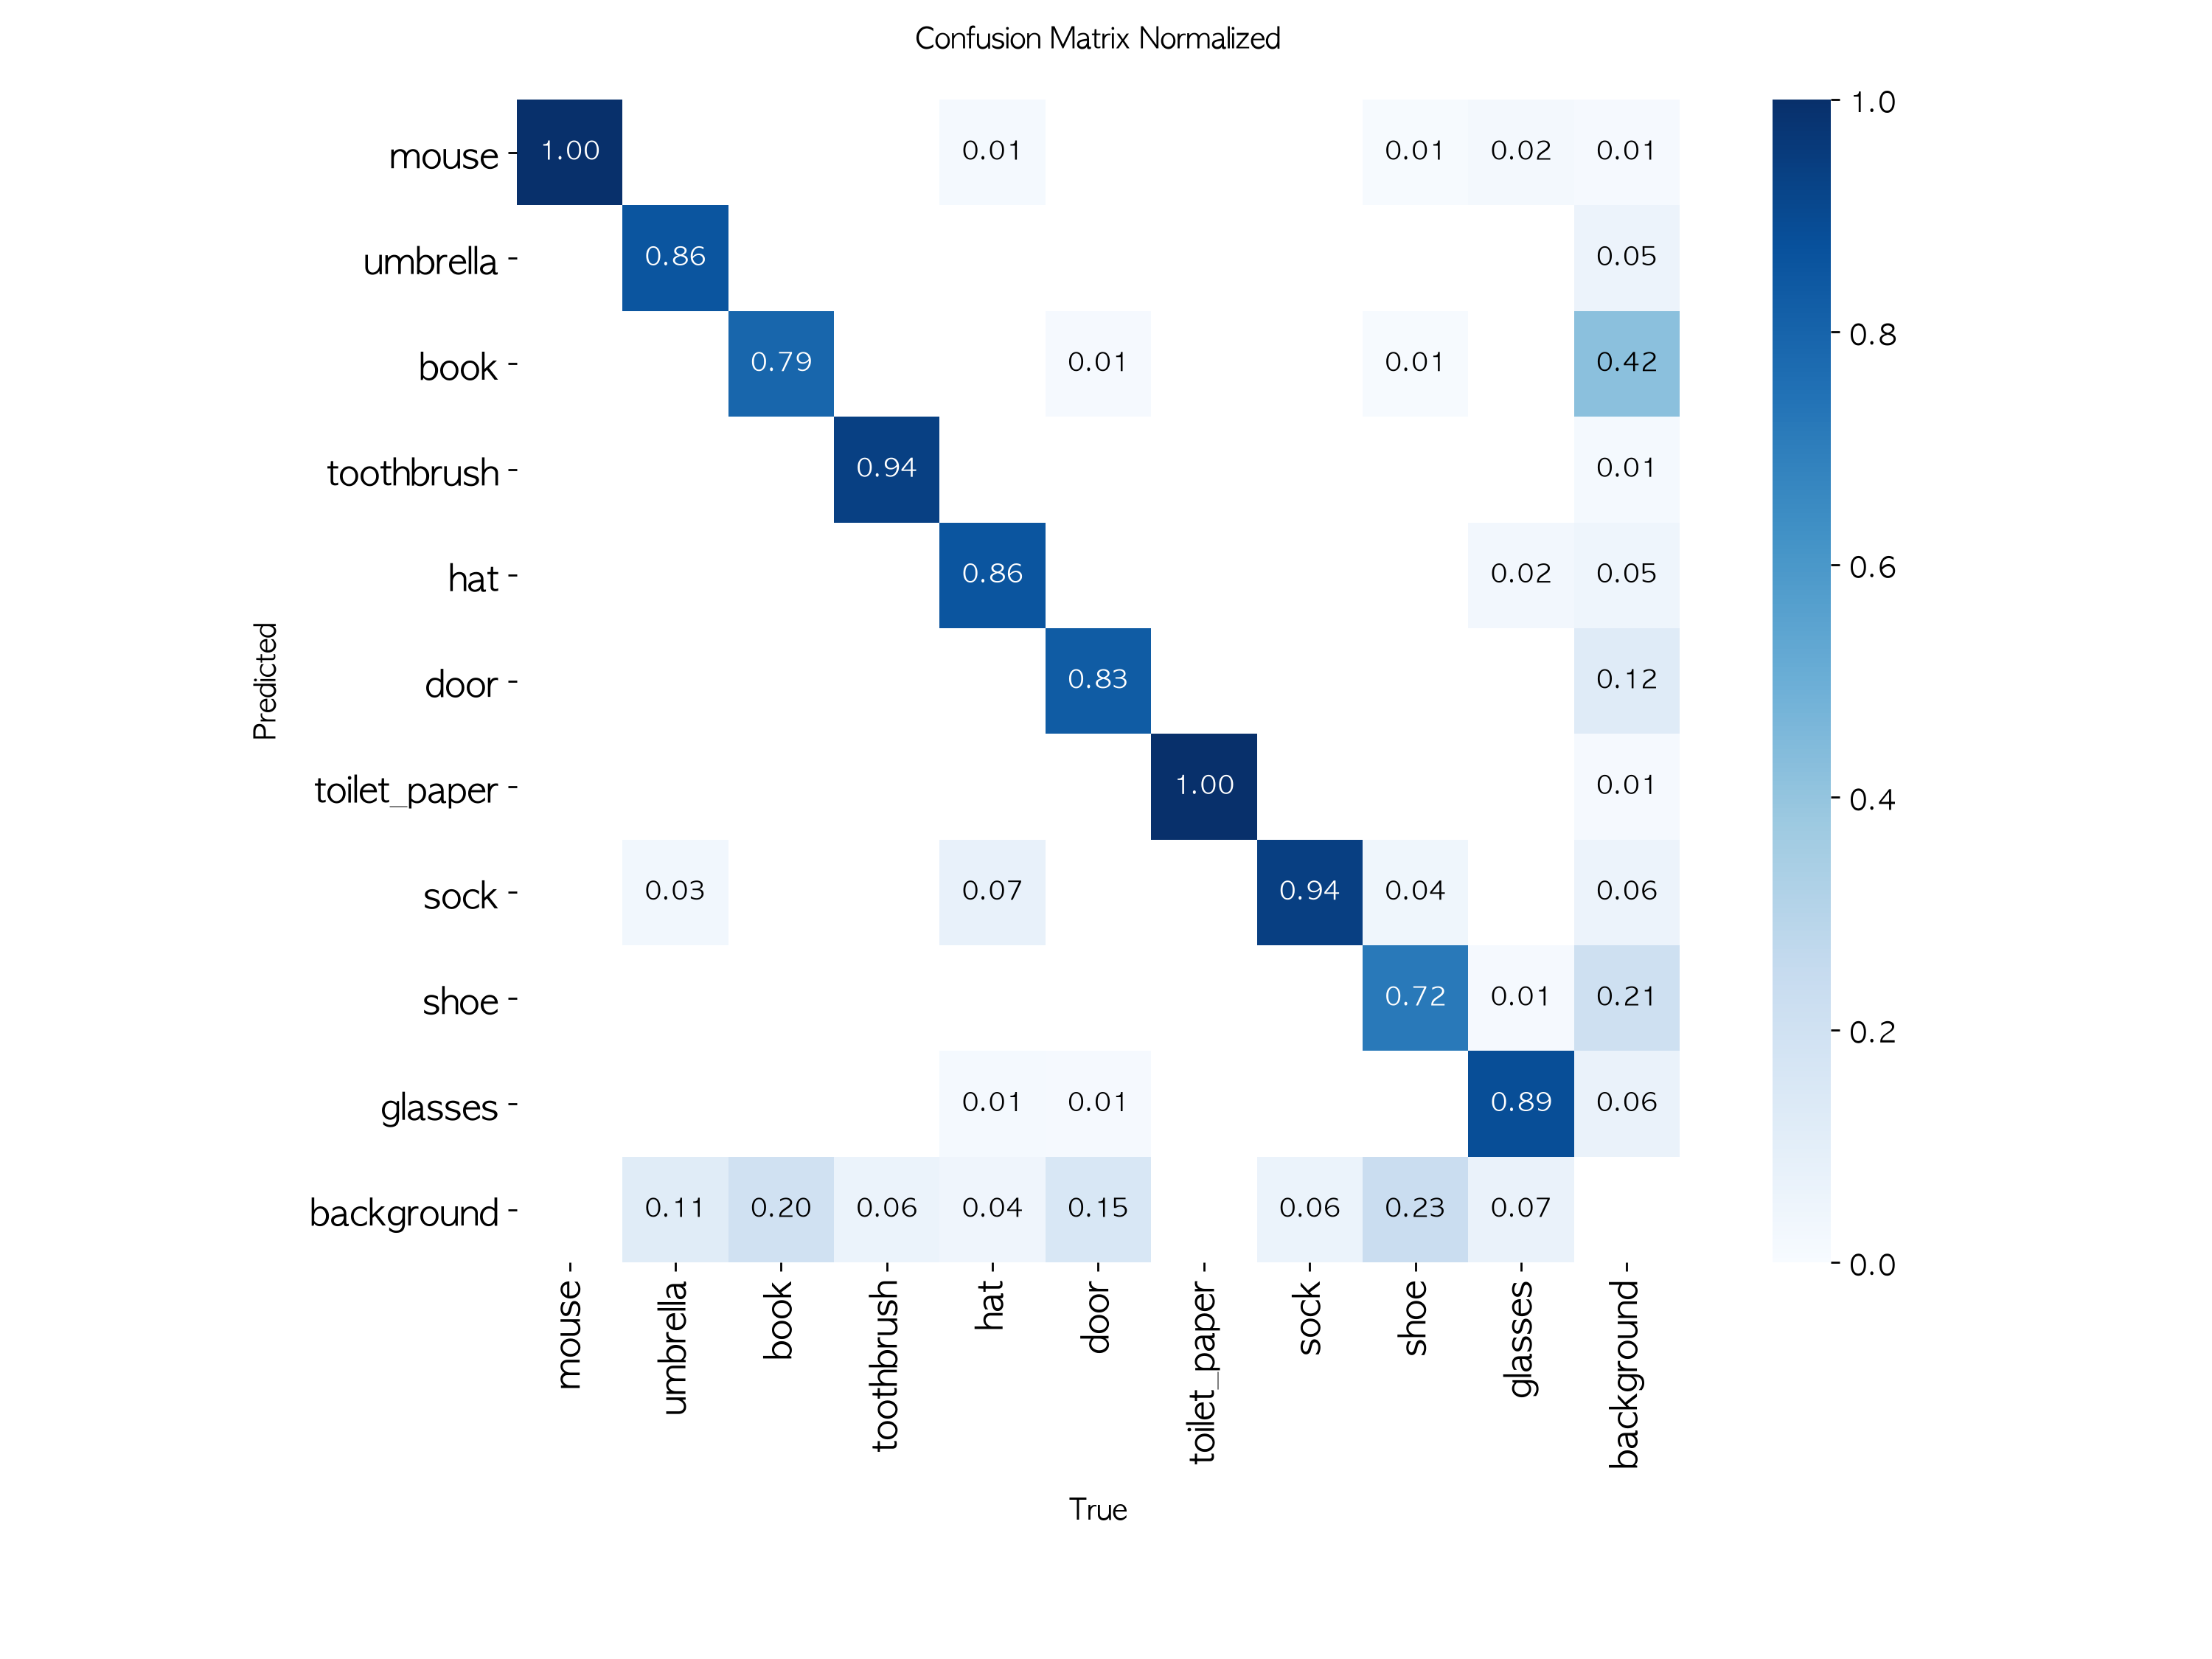

In [13]:
BEST = max(EXPS, key=lambda n: results[n].loc['전체', 'mAP50'])
print('앱에 쓸 모델:', BEST)
display(Image(str(RUNS / f'{BEST}_val' / 'confusion_matrix_normalized.png'), width=700))

혼동행렬에서 **양말↔신발**, **안경↔배경**을 먼저 보자. 아래는 정답(왼쪽)과 예측(오른쪽) 예시.

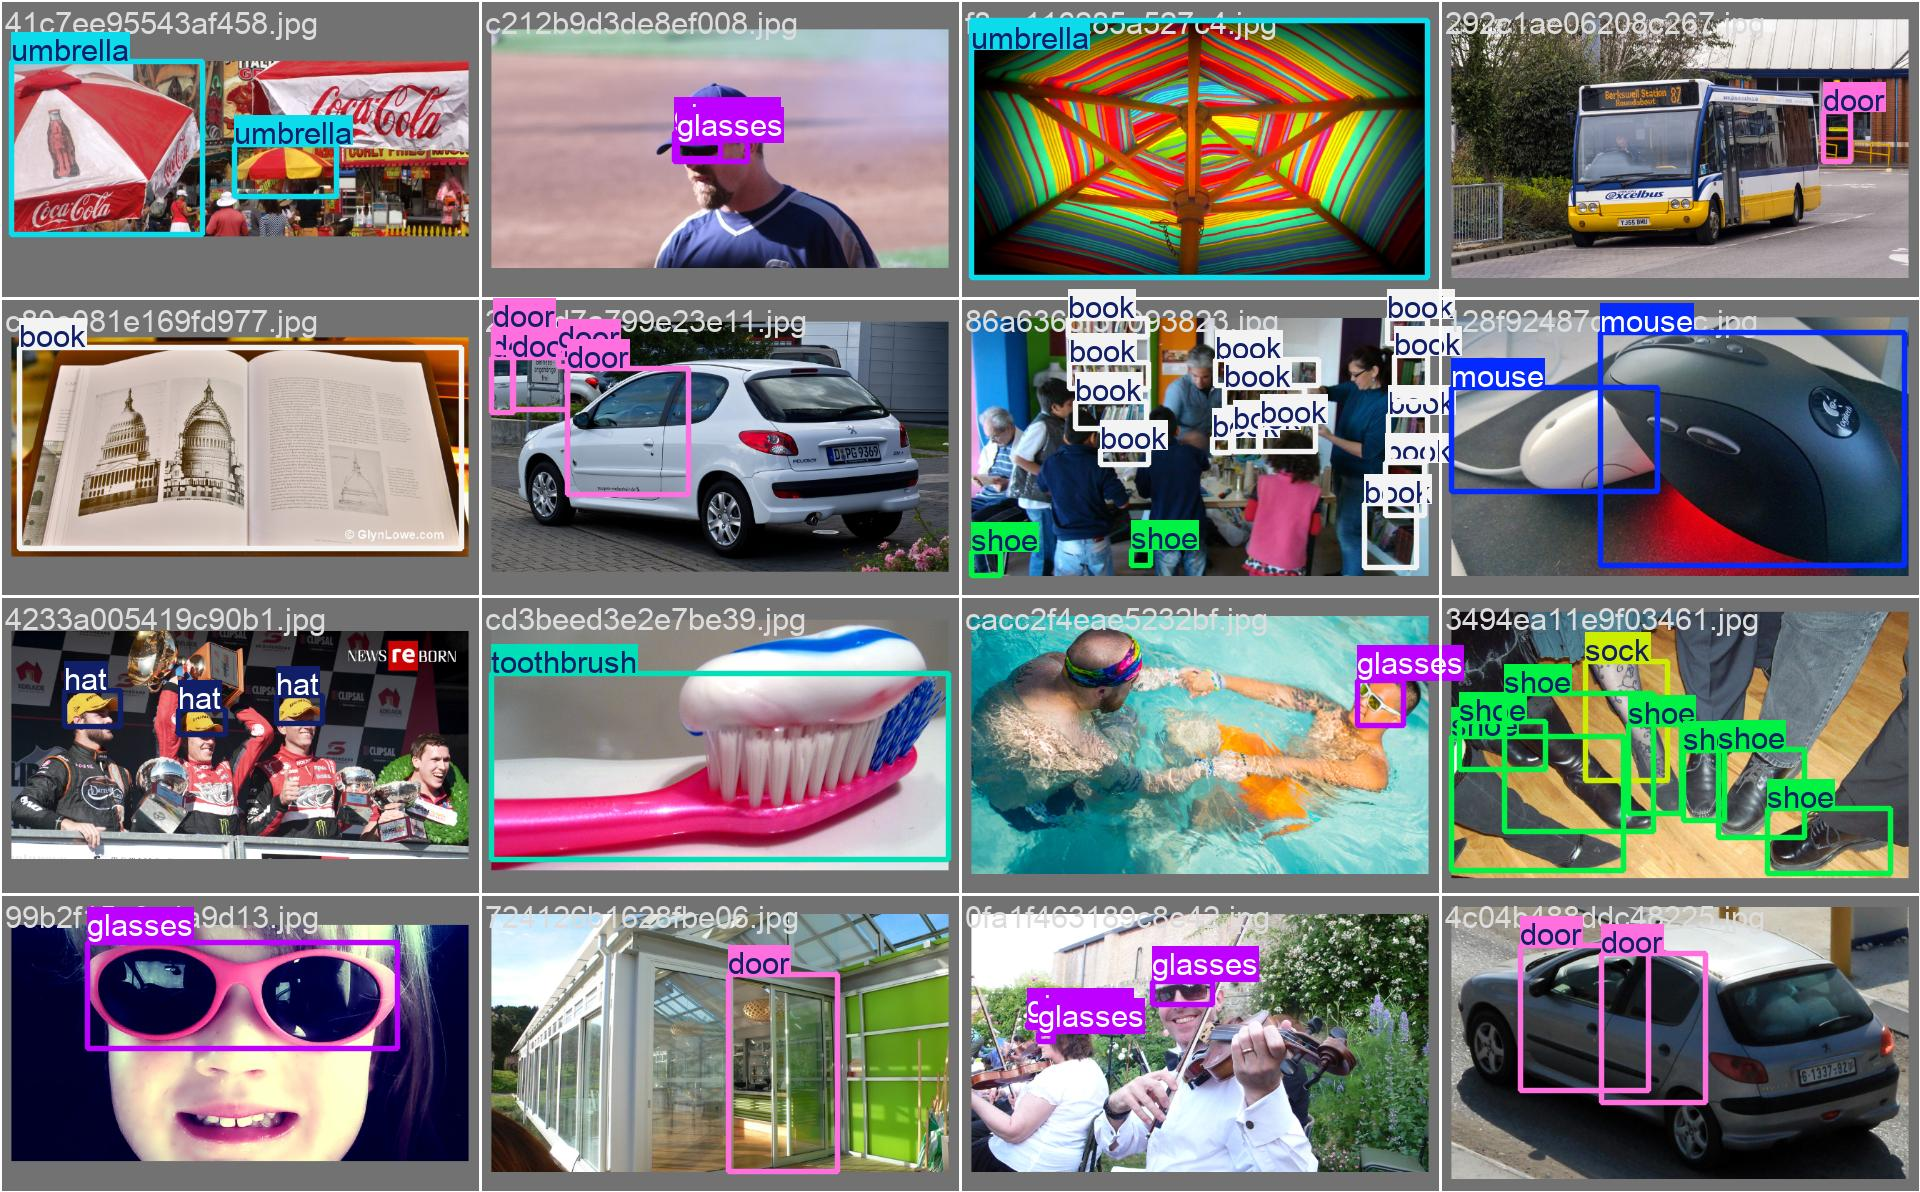

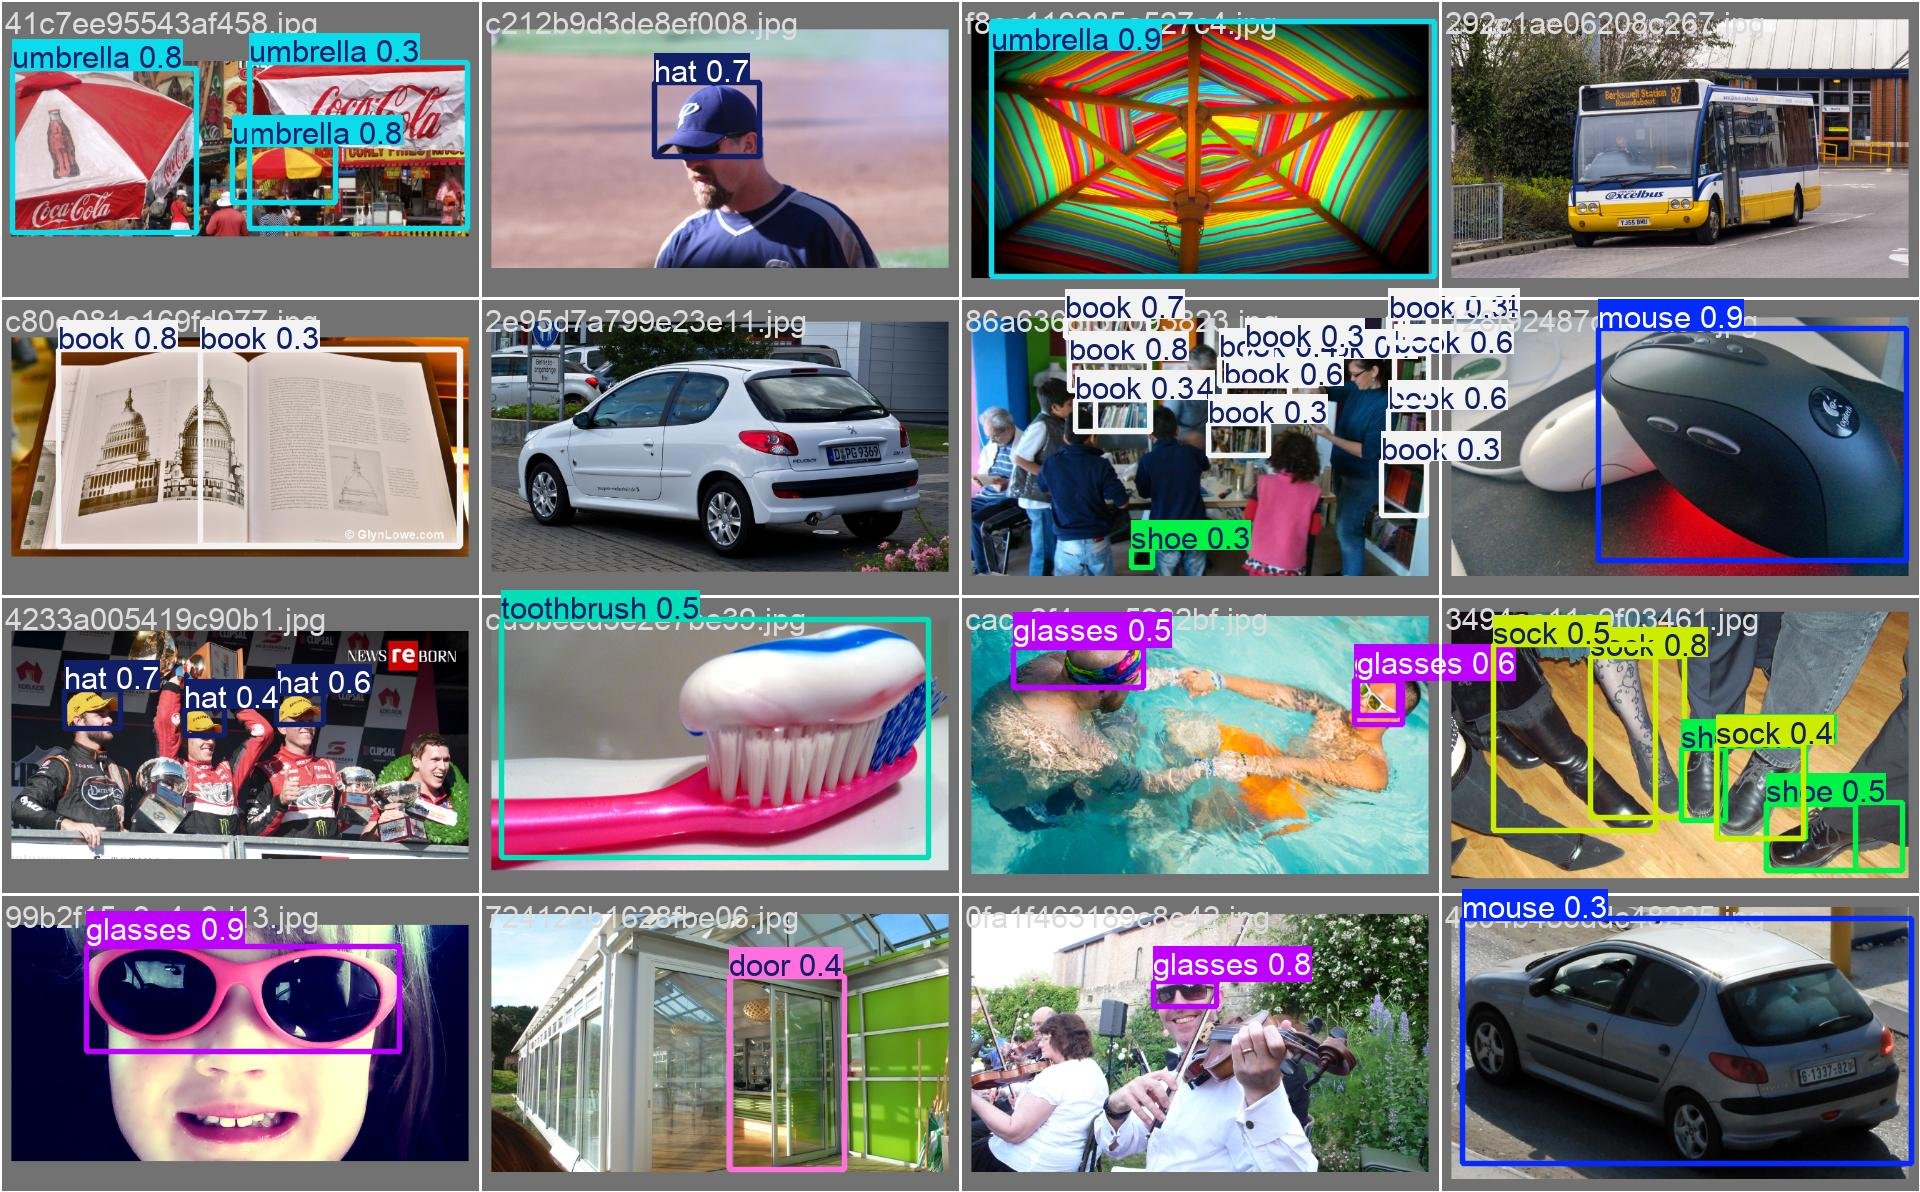

In [14]:
for kind in ['labels', 'pred']:
    display(Image(str(RUNS / f'{BEST}_val' / f'val_batch0_{kind}.jpg'), width=900))

## 8. ONNX 내보내기 + 웹앱과 같은 계산으로 검증

웹앱은 스캔 틀을 320×320으로 잘라 넣는다. 그래서 `imgsz=320`으로 내보낸다.

In [15]:
import onnxruntime as ort
onnx_path = Path(models[BEST].export(format='onnx', imgsz=320, opset=12, simplify=True, dynamic=False))
sess = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
print('입력:', sess.get_inputs()[0].shape, '| 출력:', sess.get_outputs()[0].shape)   # [1,3,320,320] → [1,14,2100]

Ultralytics 8.4.208 🚀 Python-3.12.15 torch-2.15.0 CPU (Apple M4 Pro)


YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 1.6 GFLOPs



PyTorch: starting from '/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/A_full/weights/best.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 14, 2100) (5.3 MB)



ONNX: starting export with onnx 1.23.2 opset 12...


ONNX: slimming with onnxslim 0.1.99...


ONNX: export success ✅ 0.9s, saved as '/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/A_full/weights/best.onnx' (10.1 MB)



Export complete (1.0s)
Results saved to /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/A_full/weights/best.onnx
Predict:         yolo predict task=detect model=/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/A_full/weights/best.onnx imgsz=320 
Validate:        yolo val task=detect model=/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/A_full/weights/best.onnx imgsz=320 data=/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/yolo/dataset.yaml 
Visualize:       https://netron.app


입력: [1, 3, 320, 320] | 출력: [1, 14, 2100]


In [ ]:
# 같은 사진에 대해 ① ultralytics(PyTorch) 예측 ② 우리 전처리 + ONNX + 우리 후처리(src/postprocess.py) 비교
import cv2
checked = 0ㅌ
for lab in sorted((YOLO_DIR / 'labels' / 'val').glob('*.txt'))[:30]:
    img = cv2.imread(str(next((YOLO_DIR / 'images' / 'val').glob(lab.stem + '.*'))))
    tensor, crop = E.preprocess(img)
    ours = E.run_onnx(sess, tensor)
    ref = models[BEST].predict(crop, imgsz=320, conf=E.CONF, iou=E.IOU, device='cpu', verbose=False)[0].boxes
    if len(ref) == 0 and len(ours) == 0: continue
    # 신뢰도 0.5 경계에 걸린 박스 하나 정도는 부동소수 차이로 갈릴 수 있다 → 1개 차이까지 허용
    assert abs(len(ours) - len(ref)) <= 1, (lab.name, len(ours), len(ref))
    if len(ref) and len(ours):
        top_ref = int(ref.cls[ref.conf.argmax()]); top_ours = max(ours, key=lambda d: d['score'])['cls']
        assert top_ref == top_ours, lab.name
    checked += 1
print(f'✅ {checked}장에서 박스 수(±1) · 최고 점수 클래스 일치')

✅ 17장에서 박스 수(±1) · 최고 점수 클래스 일치


In [17]:
# 웹앱으로 복사
DOCS = ROOT / 'docs'
shutil.copy(onnx_path, DOCS / 'model.onnx')
(DOCS / 'classes.js').write_text(C.to_js())
print('docs/model.onnx', round((DOCS / 'model.onnx').stat().st_size / 1e6, 1), 'MB')

docs/model.onnx 10.5 MB


## 9. 직접 찍은 사진으로 미션 통과율

`my_photos/<클래스키>/*.jpg` 에 사진을 넣는다 (예: `my_photos/sock/1.jpg`). 웹앱과 **같은 규칙**(가운데 틀 · 면적 15% · 신뢰도 0.5)으로 판정한다.

In [18]:
PHOTOS = ROOT / 'my_photos'
if PHOTOS.exists() and any(PHOTOS.rglob('*.jpg')):
    mine = E.my_photos_table(sess, PHOTOS)
    display(mine.groupby('미션')['통과'].agg(['mean', 'count']).rename(columns={'mean': '통과율', 'count': '장수'}))
    display(mine[~mine['통과']])
else:
    print('my_photos/ 에 사진을 넣고 다시 실행하세요.')

my_photos/ 에 사진을 넣고 다시 실행하세요.


## 10. 정리 — 스터디에서 이야기할 것

1. **사전학습 + 파인튜닝**: 클래스 층만 새로 만들고 나머지는 COCO에서 가져온다. 400장씩으로 새 물건 6종을 배운다.
2. **전체 미세조정 vs 백본 고정**: 위 표의 A/B 차이. 백본을 고정하면 빠르지만 새 물건을 덜 배우는가?
3. **기존 4종**: 기준선 대비 나빠졌나? (클래스 층이 새로 초기화됐는데도 400장으로 회복하는가)
4. **헷갈린 쌍**: 혼동행렬의 양말↔신발 · 빠진 라벨 함정
5. **시그모이드 vs softmax**: YOLO 클래스 점수는 서로 독립
6. **웹앱으로 옮기기**: 후처리(decode · NMS)를 직접 짜서 PyTorch와 같은 결과인지 확인했다